# Sesión 6 — Laboratorio: validación y perfilado de grupos con Wine

Demostración de la validación de un agrupamiento sobre el conjunto Wine (178 vinos, 13 medidas
químicas, 3 cultivares). El cultivar **no** se usa para agrupar: sólo para evaluar al final.

Pasos: elegir $k$ con índices internos, comparar algoritmos, medir la estabilidad por remuestreo,
perfilar los grupos y describirlos con reglas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.tree import DecisionTreeClassifier, export_text

## Paso 1: elegir $k$ con índices internos

Las medidas tienen unidades muy distintas (la prolina vale cientos; el tono, alrededor de 1), así que se estandarizan.

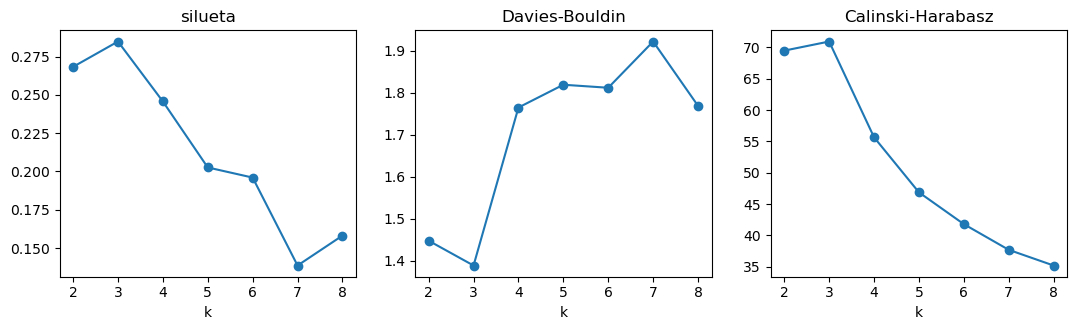

,silueta,Davies-Bouldin,Calinski-Harabasz
k,,,
2,0.27,1.45,69.49
3,0.28,1.39,70.94
4,0.25,1.77,55.67
5,0.20,1.82,46.88
6,0.20,1.81,41.81
7,0.14,1.92,37.71
8,0.16,1.77,35.21


In [2]:
wine = load_wine()
X = StandardScaler().fit_transform(wine.data)
cultivar = wine.target

filas = []
for k in range(2, 9):
    z = KMeans(k, n_init=10, random_state=0).fit_predict(X)
    filas.append((k, silhouette_score(X, z), davies_bouldin_score(X, z), calinski_harabasz_score(X, z)))
indices = pd.DataFrame(filas, columns=["k", "silueta", "Davies-Bouldin", "Calinski-Harabasz"]).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, indices.columns):
    indices[col].plot(ax=ax, marker="o", title=col)
plt.show()
indices.round(2)

## Paso 2: comparar algoritmos con $k = 3$

In [3]:
modelos = {"k-medias": KMeans(3, n_init=10, random_state=0),
           "Ward": AgglomerativeClustering(3, linkage="ward"),
           "Promedio": AgglomerativeClustering(3, linkage="average"),
           "GMM": GaussianMixture(3, n_init=10, random_state=0)}
filas = []
for nombre, modelo in modelos.items():
    z = modelo.fit_predict(X)
    filas.append((nombre, list(np.bincount(z)),
                  silhouette_score(X, z), davies_bouldin_score(X, z), calinski_harabasz_score(X, z),
                  adjusted_rand_score(cultivar, z), normalized_mutual_info_score(cultivar, z)))
pd.DataFrame(filas, columns=["modelo", "tamaños", "silueta", "DB", "CH", "ARI", "NMI"]).set_index("modelo").round(2)

,tamaños,silueta,DB,CH,ARI,NMI
modelo,,,,,,
k-medias,"[65, 51, 62]",0.28,1.39,70.94,0.90,0.88
Ward,"[58, 56, 64]",0.28,1.42,67.65,0.79,0.79
Promedio,"[174, 1, 3]",0.16,1.03,4.03,-0.01,0.02
GMM,"[51, 63, 64]",0.28,1.39,70.69,0.88,0.86


El enlace promedio deja casi todos los vinos en un grupo y, aun así, tiene el **mejor** Davies-Bouldin:
un solo índice puede engañar. ARI y NMI comparan con el cultivar, que los modelos no usan.

## Paso 3: estabilidad por remuestreo

Dos submuestras del 80 %, un modelo en cada una, y el ARI entre las particiones que asignan a **todos** los vinos.
Se repite 50 veces para cada $k$.

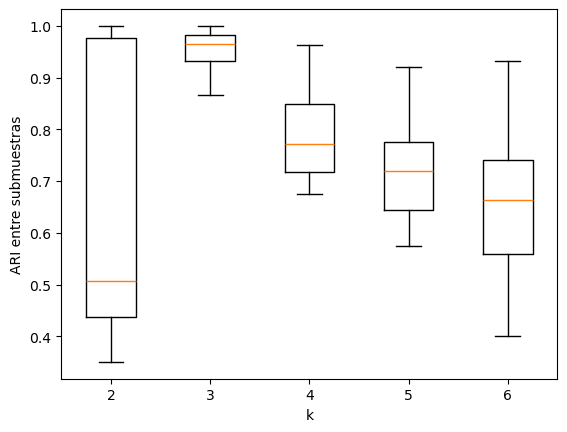

,2,3,4,5,6
media,0.69,0.96,0.79,0.72,0.66
mínimo,0.35,0.87,0.67,0.58,0.40


In [4]:
def estabilidad(X, k, B=50, f=0.8, semilla=0):
    rng, n, r = np.random.default_rng(semilla), len(X), []
    for b in range(B):
        i = rng.choice(n, int(f * n), replace=False)
        j = rng.choice(n, int(f * n), replace=False)
        m1 = KMeans(k, n_init=10, random_state=b).fit(X[i])
        m2 = KMeans(k, n_init=10, random_state=1000 + b).fit(X[j])
        r.append(adjusted_rand_score(m1.predict(X), m2.predict(X)))
    return np.array(r)

est = {k: estabilidad(X, k) for k in range(2, 7)}
plt.boxplot(list(est.values()))
plt.xticks(range(1, len(est) + 1), list(est.keys()))
plt.xlabel("k"); plt.ylabel("ARI entre submuestras"); plt.show()
pd.DataFrame({k: (r.mean(), r.min()) for k, r in est.items()}, index=["media", "mínimo"]).round(2)

## Paso 4: perfil de los grupos

tamaños: [65 51 62]


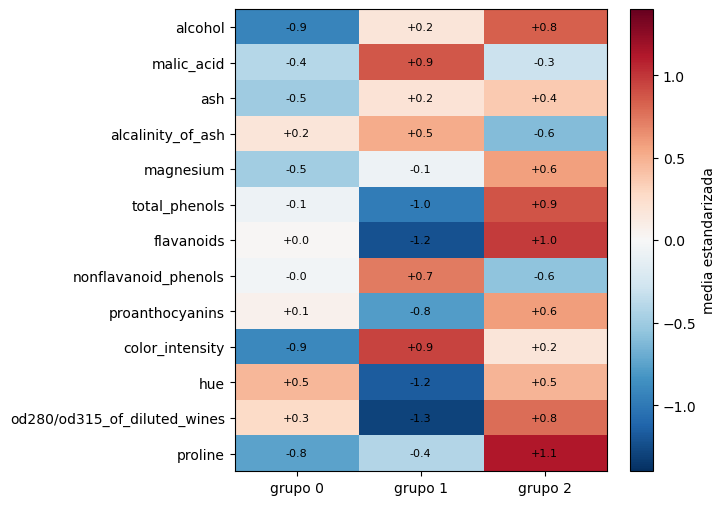

,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


In [5]:
z = KMeans(3, n_init=10, random_state=0).fit_predict(X)
print("tamaños:", np.bincount(z))
perfil_z = pd.DataFrame(X, columns=wine.feature_names).groupby(z).mean().T     # estandarizado
perfil = pd.DataFrame(wine.data, columns=wine.feature_names).groupby(z).mean().T  # unidades originales

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(perfil_z.values, cmap="RdBu_r", vmin=-1.4, vmax=1.4, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels([f"grupo {g}" for g in range(3)])
ax.set_yticks(range(len(perfil_z))); ax.set_yticklabels(perfil_z.index)
for i in range(perfil_z.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{perfil_z.values[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="media estandarizada"); plt.show()
perfil.round(2)

## Paso 5: reglas que describen los grupos

In [6]:
arbol = DecisionTreeClassifier(max_depth=2, random_state=0).fit(wine.data, z)   # unidades originales
print(export_text(arbol, feature_names=wine.feature_names))
print("vinos cuyo grupo reproduce el árbol:", round((arbol.predict(wine.data) == z).mean(), 3))
print()
print(pd.crosstab(z, cultivar, rownames=["grupo"], colnames=["cultivar"]))

|--- proline <= 755.00
|   |--- od280/od315_of_diluted_wines <= 2.19
|   |   |--- class: 1
|   |--- od280/od315_of_diluted_wines >  2.19
|   |   |--- class: 0
|--- proline >  755.00
|   |--- flavanoids <= 2.17
|   |   |--- class: 1
|   |--- flavanoids >  2.17
|   |   |--- class: 2

vinos cuyo grupo reproduce el árbol: 0.938

cultivar   0   1   2
grupo               
0          0  65   0
1          0   3  48
2         59   3   0


## Conclusiones

* Silueta, Davies-Bouldin, Calinski-Harabasz y la estabilidad coinciden en $k = 3$.
* Un solo índice puede engañar: Davies-Bouldin prefiere una partición inútil (174, 1, 3); hay que mirar los tamaños.
* La estabilidad distingue $k = 3$ con claridad.
* El perfil estandarizado y un árbol de dos niveles describen los grupos en términos químicos.
* Los grupos coinciden casi por completo con los cultivares (ARI 0.90), aunque nunca se usaron.